In [2]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 390.1 kB/s eta 0:00:28
   - ------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Задание 3
Требуемые условия завершения

Выбрать 2 акции.

1. Найти эффективный портфель:
    a) с минимальным риском;
    б) с максимальной доходностью при заданном уровне риска;
    в) максимизирующий функцию полезности Марковица.
2. Построить график коэффициента Шарпа.
3. Найти касательный портфель.
4. Сделать выводы и оформить отчет.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from statsmodels.graphics.gofplots import qqplot

In [13]:
def load_returns(path):
    df = pd.read_csv(path, sep=None, engine='python')
    df['date'] = pd.to_datetime(df['date'])
    df = df.sort_values('date')
    df['log_ret'] = np.log(df['close'] / df['close'].shift(1))
    return df.dropna().reset_index(drop=True)

df1 = load_returns('data/PLZL.csv')
df1 = df1.tail(400)
df1 = df1[df1['date'] != '2025-03-27'].reset_index(drop=True)
df1['log_ret'] = np.log(df1['close'] / df1['close'].shift(1))
df1 = df1.dropna().reset_index(drop=True)
df2 = load_returns('data/SNGS.csv')
df2 = df2.tail(400)

In [18]:
df1 = load_returns('data/PLZL.csv').tail(400).reset_index(drop=True)

split_date = pd.Timestamp('2025-03-27')
before = df1.loc[df1['date'] < split_date, 'close'].iloc[-1]
after  = df1.loc[df1['date'] == split_date, 'close'].iloc[0]
factor = before / after          # ≈ 10
print(f'factor ≈ {factor:.2f}')

df1.loc[df1['date'] < split_date, 'close'] /= factor
df1['log_ret'] = np.log(df1['close'] / df1['close'].shift(1))
df1 = df1.dropna().reset_index(drop=True)

factor ≈ 10.18


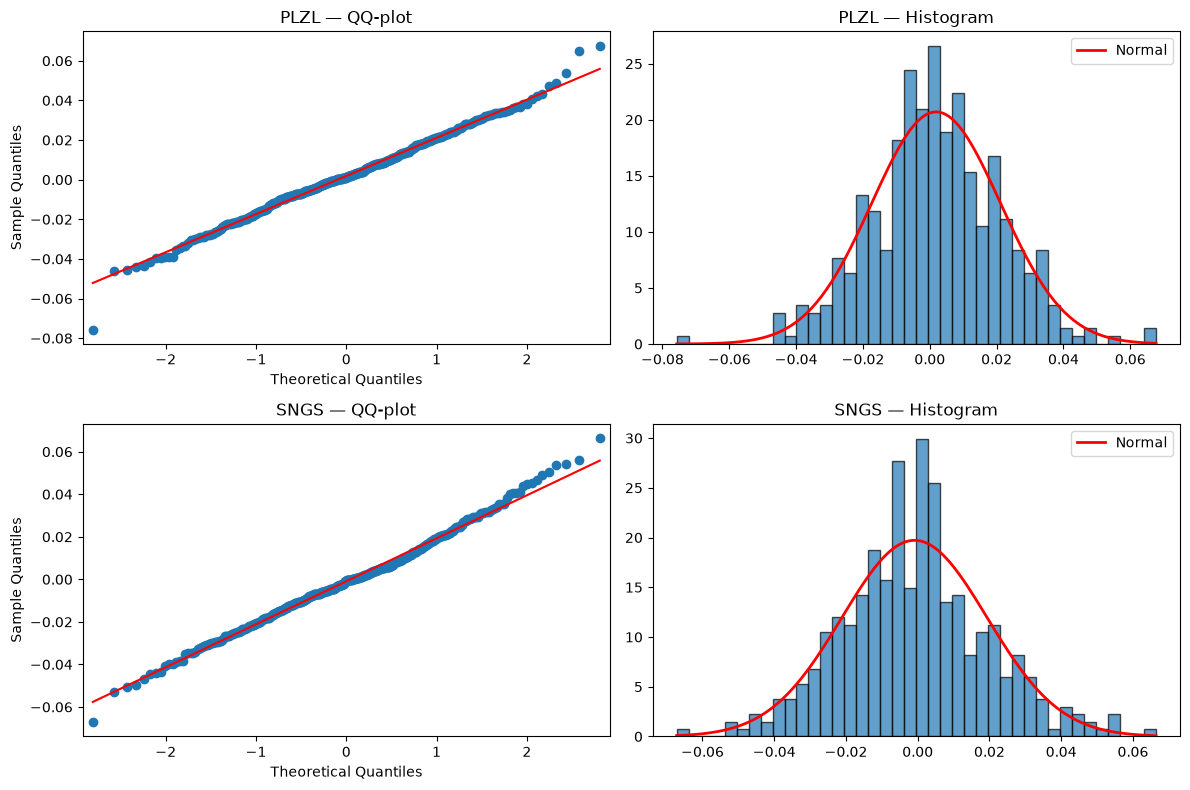

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, (name, df) in enumerate([('PLZL', df1), ('SNGS', df2)]):
    r = df['log_ret']

    qqplot(r, line='s', ax=axes[i, 0])
    axes[i, 0].set_title(f'{name} — QQ-plot')

    axes[i, 1].hist(r, bins=40, density=True, alpha=0.7, edgecolor='k')
    x = np.linspace(r.min(), r.max(), 200)
    axes[i, 1].plot(x, stats.norm.pdf(x, r.mean(), r.std()), 'r-', lw=2, label='Normal')
    axes[i, 1].set_title(f'{name} — Histogram')
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Выравниваем по датам, чтобы доходности соответствовали одним и тем же дням
m = df1[['date','log_ret']].merge(df2[['date','log_ret']], on='date', suffixes=('_1','_2'))
R = m[['log_ret_1','log_ret_2']].values          # Матрица активов двух акций (T, 2)
n = R.shape[1]

mu    = R.mean(axis=0)                           # средняя дневная лог-доходность каждого актива;
Sigma = np.cov(R, rowvar=False, ddof=1)          # выборочная ковариация (ddof=1 — несмещённая оценка, делим на T−1).

p = np.linalg.solve(Sigma, mu)                   # p = Σ⁻¹μ
q = np.linalg.solve(Sigma, np.ones(n))           # q = Σ⁻¹1

A = mu @ p                                       # A = μᵀΣ⁻¹μ «доходность в квадрате», взвешенная через
B = mu @ q                                       # B = μᵀΣ⁻¹1  ( = 1ᵀΣ⁻¹μ ) перекрёстный член;
C = np.ones(n) @ q                               # C = 1ᵀΣ⁻¹1 «дисперсионный масштаб»;
D = A*C - B**2                                   # по неравенству Коши–Буняковского D > 0, пока μ не пропорционален 1.

def stats(w):
    return float(mu @ w), float(np.sqrt(w @ Sigma @ w))

# Минимальный риск

In [23]:
w_min = q / C
print('(a) w_min =', w_min)
print('    ret, σ =', stats(w_min), '  сумма весов =', w_min.sum())

(a) w_min = [0.53649152 0.46350848]
    ret, σ = (0.0005475123490093235, 0.01624165605082873)   сумма весов = 1.0


# Максимум доходностей

In [25]:
sigma_star = 0.14

if sigma_star < 1/np.sqrt(C):
    print('σ* меньше минимального риска портфеля')
else:
    mu_star = (B + np.sqrt(D*(C*sigma_star**2 - 1))) / C
    w_b = ((mu_star*C - B)*p + (A - mu_star*B)*q) / D
    print('(b) w =', w_b)
    print('    ret, σ =', stats(w_b), '  сумма весов =', w_b.sum())

(b) w = [ 6.77048846 -5.77048846]
    ret, σ = (0.017677758487799306, 0.13999999999999999)   сумма весов = 0.9999999999999982


# Полезность Марковица

In [26]:
lam = 10                          # коэффициент неприятия риска

w_c = w_min + (p - (B/C)*q) / lam
print('(c) w =', w_c)
print('    ret, σ =', stats(w_c), '  сумма весов =', w_c.sum())

(c) w = [ 1.08877095 -0.08877095]
    ret, σ = (0.0020651073373210184, 0.020385065369151776)   сумма весов = 0.9999999999999998


In [27]:
for name, w in [('a', w_min), ('b', w_b), ('c', w_c)]:
    r, s = stats(w)
    print(f'{name}: ret={r:.5f}  σ={s:.5f}  sum(w)={w.sum():.4f}  '
          f'U(λ=10)={r - 5*s**2:.5f}')

a: ret=0.00055  σ=0.01624  sum(w)=1.0000  U(λ=10)=-0.00077
b: ret=0.01768  σ=0.14000  sum(w)=1.0000  U(λ=10)=-0.08032
c: ret=0.00207  σ=0.02039  sum(w)=1.0000  U(λ=10)=-0.00001


In [43]:
rf = 0.14   # безрисковая ставка (дневная)

# --- касательный портфель (максимум Шарпа) ---
w_tan = p / B
mu_tan, sig_tan = stats(w_tan)
sharpe_max = (mu_tan - rf) / sig_tan
print(f'w_tan = {w_tan.round(4)}')
print(f'μ_tan = {mu_tan:.5f}, σ_tan = {sig_tan:.5f}, Sharpe = {sharpe_max:.4f}')
print(f'проверка √A = {np.sqrt(A):.4f}')

# --- сетка вдоль эффективной границы ---
mu_lo  = B / C                       # нижний конец (минимум σ)
mu_hi  = max(mu_tan, mu.max()) * 1.5
mu_grid = np.linspace(mu_lo, mu_hi, 300)

sigma_grid  = np.sqrt((C*mu_grid**2 - 2*B*mu_grid + A) / D)
sharpe_grid = (mu_grid - rf) / sigma_grid

w_tan = [ 3.1974 -2.1974]
μ_tan = 0.00786, σ_tan = 0.06154, Sharpe = -2.1474
проверка √A = 0.1277


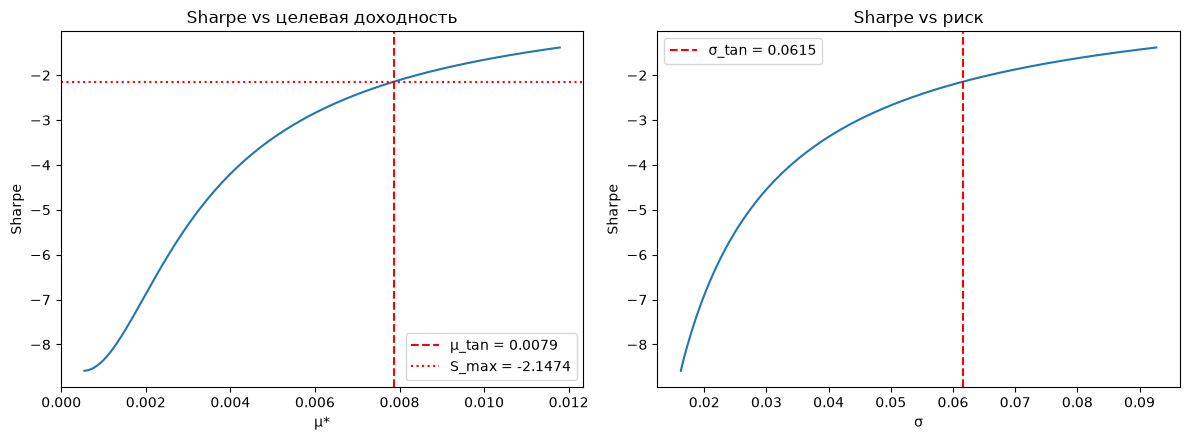

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(mu_grid, sharpe_grid)
ax[0].axvline(mu_tan, color='r', ls='--', label=f'μ_tan = {mu_tan:.4f}')
ax[0].axhline(sharpe_max, color='r', ls=':', label=f'S_max = {sharpe_max:.4f}')
ax[0].set(xlabel='μ*', ylabel='Sharpe', title='Sharpe vs целевая доходность')
ax[0].legend()

ax[1].plot(sigma_grid, sharpe_grid)
ax[1].axvline(sig_tan, color='r', ls='--', label=f'σ_tan = {sig_tan:.4f}')
ax[1].set(xlabel='σ', ylabel='Sharpe', title='Sharpe vs риск')
ax[1].legend()

plt.tight_layout()
plt.show()

In [65]:
# --- выбор безрисковой ставки ---
rf_annual = 0
rf_geo = (1 + rf_annual)**(1/252) - 1   # ≈ 0.000519 — корректный дневной эквивалент

mu_min = B / C

if rf_geo < mu_min:
    rf = rf_geo
    print(f'используем реальную ставку rf = {rf:.6f} (годовых {rf_annual:.0%})')
else:
    rf = 0.0
    print(f'rf_geo = {rf_geo:.6f} ≥ μ_min = {mu_min:.6f}: '
          f'касательный портфель на верхней ветви недостижим при этой ставке.')
    print(f'→ для учебной задачи фиксируем rf = 0 (чистая геометрия границы).')

print(f'итоговая rf = {rf:.6f}')

используем реальную ставку rf = 0.000000 (годовых 0%)
итоговая rf = 0.000000


In [66]:
# --- касательный портфель ---
denom = B - rf * C
assert abs(denom) > 1e-12, 'B − rf·C ≈ 0: rf совпадает с μ_min'

w_tan = (p - rf * q) / denom
mu_tan, sig_tan = stats(w_tan)
sharpe_tan = (mu_tan - rf) / sig_tan

print(f'w_tan  = {w_tan.round(4)}  sum = {w_tan.sum():.4f}')
print(f'μ_tan  = {mu_tan:.6f}   σ_tan = {sig_tan:.6f}   Sharpe = {sharpe_tan:.4f}')

# аналитическая сверка
mu_an = (A - rf*B) / denom
sg_an = np.sqrt(A - 2*rf*B + rf**2 * C) / abs(denom)
sh_an = np.sqrt(A - 2*rf*B + rf**2 * C)
print(f'аналитика: μ={mu_an:.6f}  σ={sg_an:.6f}  Sharpe={sh_an:.4f}')

w_tan  = [ 3.1974 -2.1974]  sum = 1.0000
μ_tan  = 0.007859   σ_tan = 0.061535   Sharpe = 0.1277
аналитика: μ=0.007859  σ=0.061535  Sharpe=0.1277


In [67]:
# --- проверки ---
lhs = C*mu_tan**2 - 2*B*mu_tan + A
rhs = D * sig_tan**2
print(f'граница: {lhs:.8f} vs {rhs:.8f}  (разница {abs(lhs-rhs):.2e})')

for name, w in [('a:min', w_min), ('b:fixed σ*', w_b), ('c:util', w_c), ('tan', w_tan)]:
    r, s = stats(w)
    print(f'{name:12s}: μ={r:+.6f}  σ={s:.6f}  S={(r-rf)/s:+.4f}')

граница: 0.21784365 vs 0.21784365  (разница 0.00e+00)
a:min       : μ=+0.000548  σ=0.016242  S=+0.0337
b:fixed σ*  : μ=+0.017678  σ=0.140000  S=+0.1263
c:util      : μ=+0.002065  σ=0.020385  S=+0.1013
tan         : μ=+0.007859  σ=0.061535  S=+0.1277


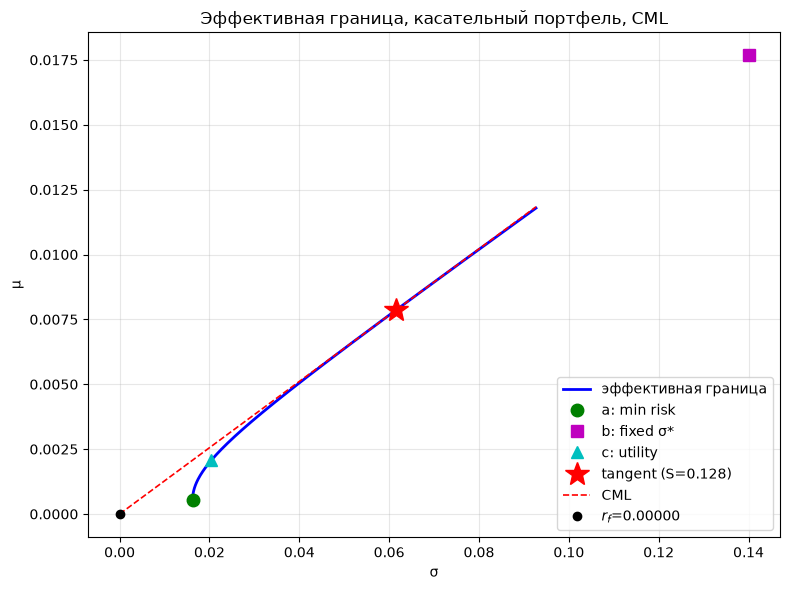

In [68]:
# --- график ---
fig, ax = plt.subplots(figsize=(8, 6))

mu_hi = max(mu_tan, mu.max()) * 1.5
mu_grid_plot = np.linspace(B/C, mu_hi, 300)
sigma_grid_plot = np.sqrt((C*mu_grid_plot**2 - 2*B*mu_grid_plot + A) / D)
ax.plot(sigma_grid_plot, mu_grid_plot, 'b-', lw=2, label='эффективная граница')

for name, (w, fmt) in {'a: min risk': (w_min, 'go'),
                       'b: fixed σ*': (w_b, 'ms'),
                       'c: utility':  (w_c, 'c^')}.items():
    r, s = stats(w)
    ax.plot(s, r, fmt, ms=9, label=name)

ax.plot(sig_tan, mu_tan, 'r*', ms=18, label=f'tangent (S={sharpe_tan:.3f})')

sig_cml = np.linspace(0, sigma_grid_plot.max(), 50)
ax.plot(sig_cml, rf + sharpe_tan*sig_cml, 'r--', lw=1.2, label='CML')
ax.plot(0, rf, 'ko', ms=6, label=f'$r_f$={rf:.5f}')

ax.set(xlabel='σ', ylabel='μ',
       title='Эффективная граница, касательный портфель, CML')
ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()